# PSTL example (host)

Point-source triple-lens photometry and astrometry from `bagle.model`, compared to a matching binary-lens (`PSBL`) model with the same first two masses.

**Units (phot+astrom)**
- Separations `sep12`, `sep13`, and `a_12` / `a_23` are in mas.
- Source and lens positions are in arcsec (plots convert to mas).

Milestone (k) host figures. Leaves plotted: `PSTL_PhotAstrom_noPar_Param1` and `PSTL_PhotAstrom_noPar_EllOrbs_Param1`.

In [1]:
%matplotlib inline
from bagle import model
import numpy as np
import matplotlib.pyplot as plt

<frozen importlib._bootstrap>:491: FutureWarning: pybind11-bound class 'celerite.solver.CholeskySolver' is using an old-style placement-new '__setstate__' which has been deprecated. See the upgrade guide in pybind11's docs. This message is only visible when compiled in debug mode.


## Static triple lens vs binary lens

Same primary and secondary masses as the PSBL comparison. The tertiary mass and `sep13` show what the third lens adds.

| Param | Value | Units |
|---|---|---|
| $m_{Lp}, m_{Ls}, m_{Lt}$ | 10, 5, 2 | $M_\odot$ |
| $t_0$ | 57000 | MJD |
| $\beta$ | 0.4 | mas |
| $sep_{12}, sep_{23}$ | 3, 2 | mas |
| $\alpha_{12}, \alpha_{13}$ | 90, 45 | deg |
| $d_L, d_S$ | 2000, 4000 | pc |
| $b_{sff}$ | 1.0 | |
| $mag_{src}$ | 18 | |

In [2]:
mLp, mLs, mLt = 10.0, 5.0, 2.0
t0 = 57000.0
xS0_E, xS0_N = np.array([0.0]), np.array([0.01])
beta = 0.4
muL_E, muL_N = 0.0, 0.0
sep12, sep13 = 3.0, 2.0
muS_E, muS_N = 4.0, -3.0
dL, dS = 2000.0, 4000.0
alpha12, alpha13 = 90.0, 45.0
b_sff = np.array([1.0])
mag_src = np.array([18.0])
dmag_Lp_Ls = np.array([20.0])
root_tol = 1e-4

pstl = model.PSTL_PhotAstrom_noPar_Param1(
    mLp, mLs, mLt, t0, xS0_E, xS0_N, beta,
    muL_E, muL_N, sep12, sep13, muS_E, muS_N, dL, dS,
    alpha12, alpha13, b_sff, mag_src, dmag_Lp_Ls, root_tol=root_tol,
)
psbl = model.PSBL_PhotAstrom_noPar_Param1(
    mLp, mLs, t0, xS0_E, xS0_N, beta,
    muL_E, muL_N, muS_E, muS_N, dL, dS,
    sep12, alpha12, b_sff, mag_src, dmag_Lp_Ls, root_tol=root_tol,
)

t = np.arange(t0 - 2.5 * pstl.tE, t0 + 2.5 * pstl.tE, 2.0)
print('tE (days)', pstl.tE, 'N_times', len(t))

tE (days) 403.6926333870058 N_times 1010


### 1. Light curve

/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13127: RuntimeWarning: invalid value encountered in divide
  dwbardz = self.m1 / (z_arr - z1.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13128: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m2 / (z_arr - z2.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13129: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m3 / (z_arr - z3.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13127: RuntimeWarning: invalid value encountered in divide
  dwbardz = self.m1 / (z_arr - z1.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13128: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m2 / (z_arr - z2.resha

findfont: Failed to find font weight normal, now using 500.


findfont: Failed to find font weight normal, now using 500.


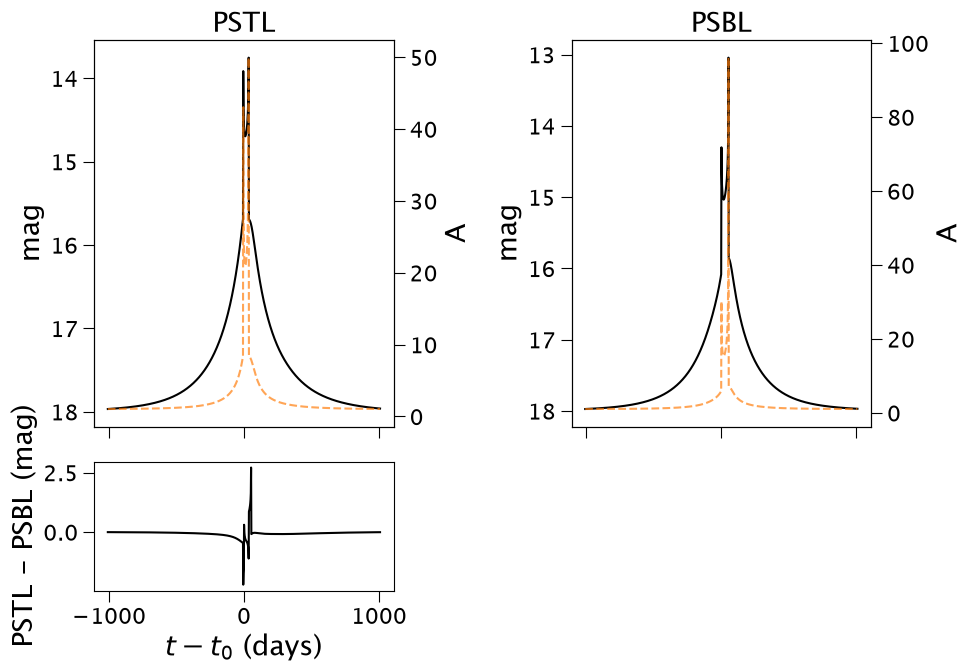

In [3]:
mag_t = np.asarray(pstl.get_photometry(t))
mag_b = np.asarray(psbl.get_photometry(t))
amp_t = np.asarray(pstl.get_amplification(t))
amp_b = np.asarray(psbl.get_amplification(t))

fig, axes = plt.subplots(
    2, 2, figsize=(10, 7), sharex='col',
    gridspec_kw=dict(height_ratios=[3, 1]))
for ax, mag, amp, title in (
    (axes[0, 0], mag_t, amp_t, 'PSTL'),
    (axes[0, 1], mag_b, amp_b, 'PSBL'),
):
    ax.plot(t - t0, mag, 'k-')
    ax.set_ylabel('mag')
    ax.invert_yaxis()
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(t - t0, amp, 'C1--', alpha=0.7)
    ax2.set_ylabel('A')

axes[1, 0].plot(t - t0, mag_t - mag_b, 'k-')
axes[1, 0].set_ylabel('PSTL - PSBL (mag)')
axes[1, 0].set_xlabel(r'$t - t_0$ (days)')
axes[1, 1].axis('off')
fig.tight_layout()
plt.show()

### 2. Unlensed astrometry

findfont: Failed to find font weight normal, now using 500.


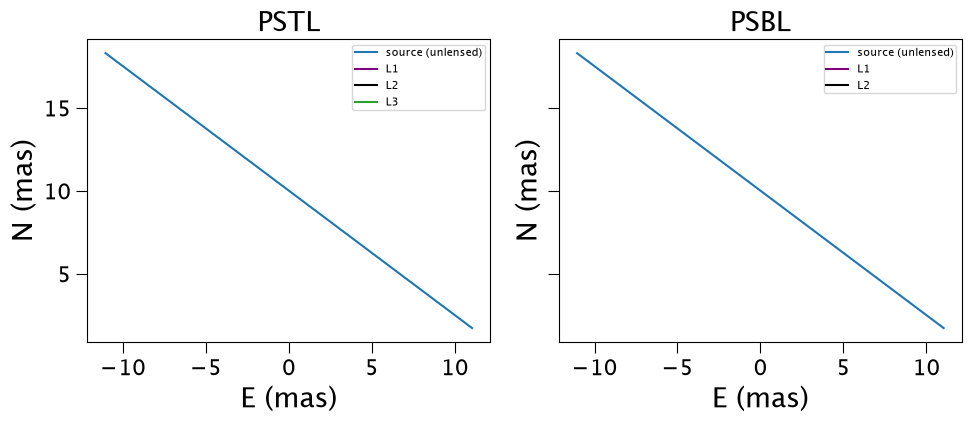

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, mod, title in ((axes[0], pstl, 'PSTL'), (axes[1], psbl, 'PSBL')):
    xS = np.asarray(mod.get_astrometry_unlensed(t))
    xL_res = np.asarray(mod.get_resolved_lens_astrometry(t))
    ax.plot(xS[:, 0] * 1e3, xS[:, 1] * 1e3, 'C0-', label='source (unlensed)')
    colors = ('purple', 'black', 'C2')
    labels = ('L1', 'L2', 'L3')
    for i in range(xL_res.shape[0]):
        ax.plot(
            xL_res[i, :, 0] * 1e3, xL_res[i, :, 1] * 1e3,
            color=colors[i], label=labels[i])
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 3. Resolved astrometry (image tracks)

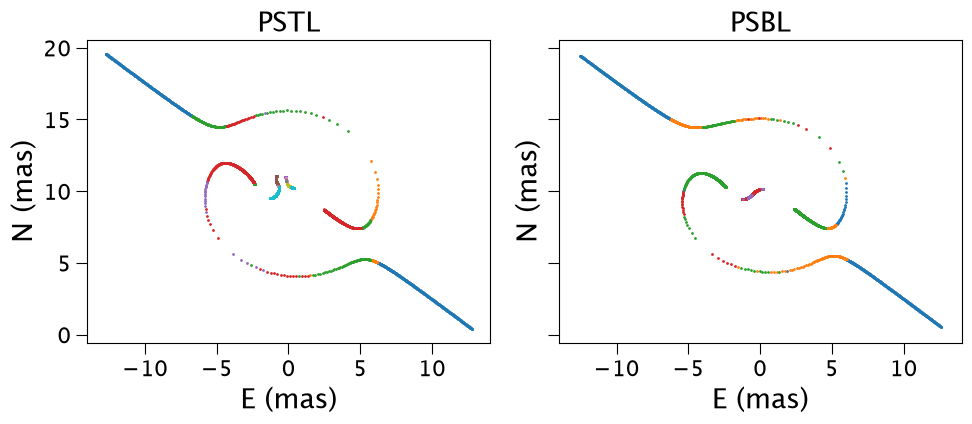

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, mod, title in ((axes[0], pstl, 'PSTL'), (axes[1], psbl, 'PSBL')):
    res = np.asarray(mod.get_resolved_astrometry(t))
    # Normalize to (N_t, N_img, 2).
    if res.ndim == 3 and res.shape[-1] == 2:
        tracks = res
    else:
        tracks = np.moveaxis(res, 0, 1)
    for i in range(tracks.shape[1]):
        xy = tracks[:, i, :]
        ok = np.isfinite(xy).all(axis=1)
        if ok.any():
            ax.plot(xy[ok, 0] * 1e3, xy[ok, 1] * 1e3, '.', ms=2, label=f'image {i}')
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_title(title)
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

### 4. Lensed astrometry and centroid shift

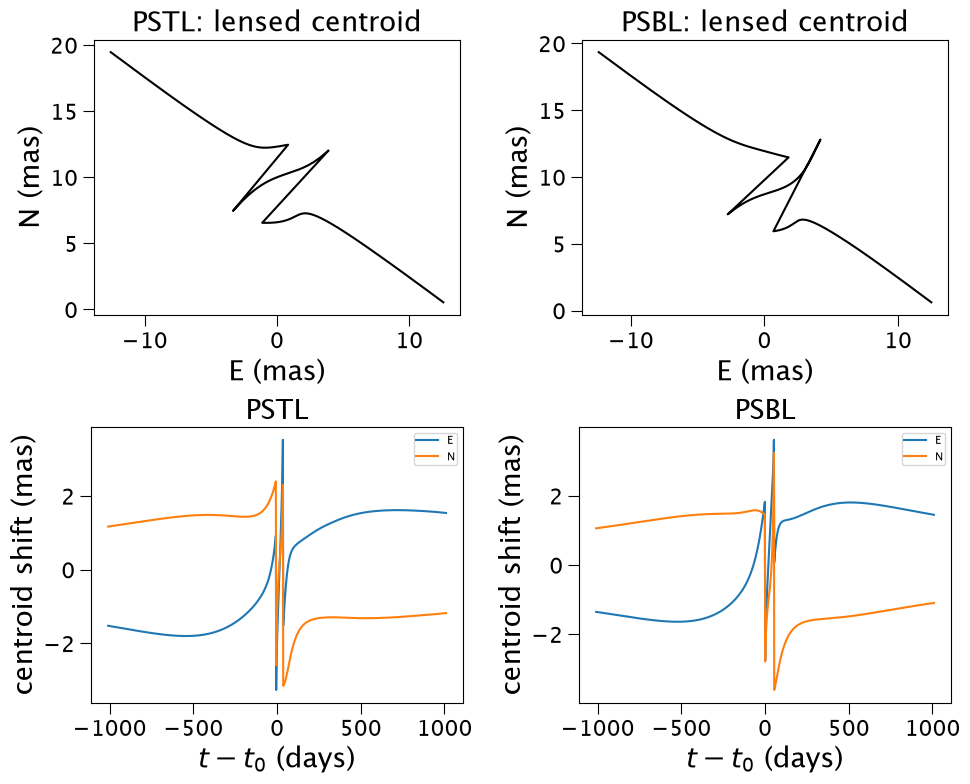

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, mod, title in ((0, pstl, 'PSTL'), (1, psbl, 'PSBL')):
    xS = np.asarray(mod.get_astrometry(t))
    shift = np.asarray(mod.get_centroid_shift(t))
    axes[0, col].plot(xS[:, 0] * 1e3, xS[:, 1] * 1e3, 'k-')
    axes[0, col].set_title(f'{title}: lensed centroid')
    axes[0, col].set_xlabel('E (mas)')
    axes[0, col].set_ylabel('N (mas)')
    axes[0, col].set_aspect('equal')
    axes[1, col].plot(t - t0, shift[:, 0], label='E')
    axes[1, col].plot(t - t0, shift[:, 1], label='N')
    axes[1, col].set_xlabel(r'$t - t_0$ (days)')
    axes[1, col].set_ylabel('centroid shift (mas)')
    axes[1, col].set_title(title)
    axes[1, col].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Keplerian triple lens (`PSTL_PhotAstrom_noPar_EllOrbs_Param1`)

Second Keplerian pair (`a_23`, `i_23`, ...) moves the tertiary relative to the secondary. Same four figure types; comparison is the static PSTL leaf above.

In [7]:
t0_com = t0
beta_com = beta
omega_pri, omega_sec = 90.0, 0.0
big_omega_sec, big_omega_ter = 0.0, 30.0
i_12, e_12, tp_12, a_12 = 30.0, 0.1, t0_com, sep12
i_23, e_23, tp_23, a_23 = 20.0, 0.05, t0_com + 50.0, sep13

pstl_orb = model.PSTL_PhotAstrom_noPar_EllOrbs_Param1(
    mLp, mLs, mLt, t0_com, xS0_E, xS0_N, beta_com,
    muL_E, muL_N,
    omega_pri, omega_sec, big_omega_sec, big_omega_ter,
    i_12, e_12, tp_12, a_12,
    i_23, e_23, tp_23, a_23,
    muS_E, muS_N, dL, dS,
    b_sff, mag_src, dmag_Lp_Ls, root_tol=root_tol,
)

t_orb = np.arange(t0_com - 2.0 * pstl_orb.tE, t0_com + 2.0 * pstl_orb.tE, 3.0)
print('EllOrbs tE', pstl_orb.tE, 'N_times', len(t_orb))

EllOrbs tE 403.6926333870058 N_times 539


### EllOrbs: light curve

/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13127: RuntimeWarning: invalid value encountered in divide
  dwbardz = self.m1 / (z_arr - z1.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13128: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m2 / (z_arr - z2.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13129: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m3 / (z_arr - z3.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13127: RuntimeWarning: invalid value encountered in divide
  dwbardz = self.m1 / (z_arr - z1.reshape((N_times, 1))) ** 2
/Users/jlu/.cursor/worktrees/pstl-k-0177d8b3/bagle-1ae08ed0085c/src/bagle/model.py:13128: RuntimeWarning: invalid value encountered in divide
  dwbardz += self.m2 / (z_arr - z2.resha

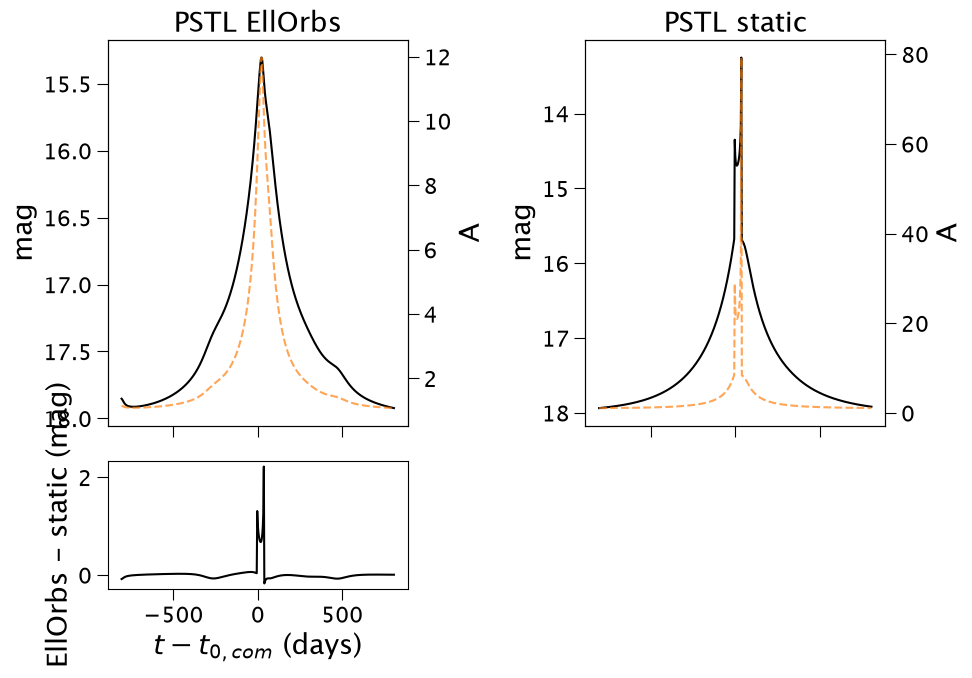

In [8]:
mag_o = np.asarray(pstl_orb.get_photometry(t_orb))
amp_o = np.asarray(pstl_orb.get_amplification(t_orb))
mag_s = np.asarray(pstl.get_photometry(t_orb))

fig, axes = plt.subplots(
    2, 2, figsize=(10, 7), sharex='col',
    gridspec_kw=dict(height_ratios=[3, 1]))
for ax, mag, amp, title in (
    (axes[0, 0], mag_o, amp_o, 'PSTL EllOrbs'),
    (axes[0, 1], mag_s, np.asarray(pstl.get_amplification(t_orb)), 'PSTL static'),
):
    ax.plot(t_orb - t0_com, mag, 'k-')
    ax.set_ylabel('mag')
    ax.invert_yaxis()
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(t_orb - t0_com, amp, 'C1--', alpha=0.7)
    ax2.set_ylabel('A')
axes[1, 0].plot(t_orb - t0_com, mag_o - mag_s, 'k-')
axes[1, 0].set_ylabel('EllOrbs - static (mag)')
axes[1, 0].set_xlabel(r'$t - t_{0,com}$ (days)')
axes[1, 1].axis('off')
fig.tight_layout()
plt.show()

### EllOrbs: unlensed / resolved / lensed astrometry

findfont: Failed to find font weight normal, now using 500.


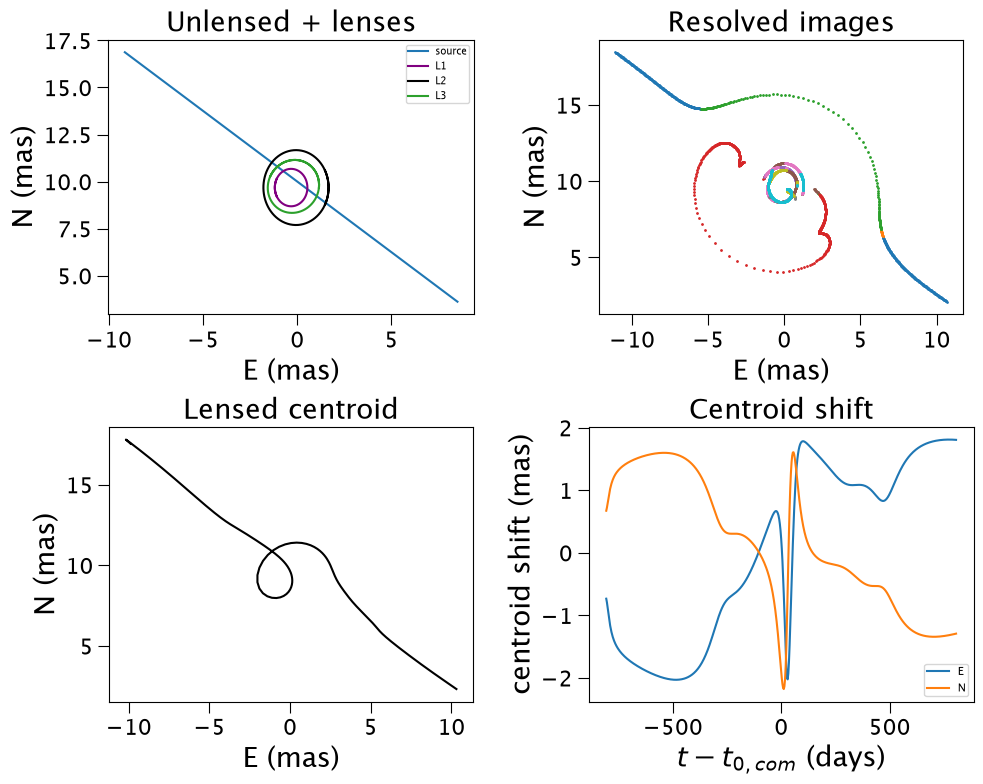

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

xS = np.asarray(pstl_orb.get_astrometry_unlensed(t_orb))
xL_res = np.asarray(pstl_orb.get_resolved_lens_astrometry(t_orb))
axes[0, 0].plot(xS[:, 0] * 1e3, xS[:, 1] * 1e3, 'C0-', label='source')
for i, c, lab in zip(range(3), ('purple', 'k', 'C2'), ('L1', 'L2', 'L3')):
    axes[0, 0].plot(xL_res[i, :, 0] * 1e3, xL_res[i, :, 1] * 1e3, color=c, label=lab)
axes[0, 0].set_title('Unlensed + lenses')
axes[0, 0].set_xlabel('E (mas)')
axes[0, 0].set_ylabel('N (mas)')
axes[0, 0].set_aspect('equal')
axes[0, 0].legend(fontsize=7)

res = np.asarray(pstl_orb.get_resolved_astrometry(t_orb))
if res.ndim == 3 and res.shape[-1] == 2:
    tracks = res
else:
    tracks = np.moveaxis(res, 0, 1)
for i in range(tracks.shape[1]):
    xy = tracks[:, i, :]
    ok = np.isfinite(xy).all(axis=1)
    if ok.any():
        axes[0, 1].plot(xy[ok, 0] * 1e3, xy[ok, 1] * 1e3, '.', ms=2)
axes[0, 1].set_title('Resolved images')
axes[0, 1].set_xlabel('E (mas)')
axes[0, 1].set_ylabel('N (mas)')
axes[0, 1].set_aspect('equal')

xS_l = np.asarray(pstl_orb.get_astrometry(t_orb))
axes[1, 0].plot(xS_l[:, 0] * 1e3, xS_l[:, 1] * 1e3, 'k-')
axes[1, 0].set_title('Lensed centroid')
axes[1, 0].set_xlabel('E (mas)')
axes[1, 0].set_ylabel('N (mas)')
axes[1, 0].set_aspect('equal')

shift = np.asarray(pstl_orb.get_centroid_shift(t_orb))
axes[1, 1].plot(t_orb - t0_com, shift[:, 0], label='E')
axes[1, 1].plot(t_orb - t0_com, shift[:, 1], label='N')
axes[1, 1].set_xlabel(r'$t - t_{0,com}$ (days)')
axes[1, 1].set_ylabel('centroid shift (mas)')
axes[1, 1].set_title('Centroid shift')
axes[1, 1].legend(fontsize=8)
fig.tight_layout()
plt.show()